# 277. Find the Celebrity
https://leetcode.com/problems/find-the-celebrity/

## Complexity Comparison

| Approach | Time | Space | Description |
|----------|------|-------|-------------|
| Brute Force | O(n^2) | O(1) | Check every pair |
| **Two-pass (Optimal)** | **O(n)** | **O(1)** | Find candidate, then verify |

## Methodology

First pass: find a candidate. Start with candidate = 0. For each person i, if candidate knows i, then candidate cannot be the celebrity, so set candidate = i. After this pass, the candidate is the only possible celebrity. Second pass: verify the candidate by checking that everyone knows the candidate and the candidate knows no one.

## Solutions

### C#

In [ ]:
/* The Knows API is defined in the parent class Relation.
   bool Knows(int a, int b); */

public class Solution : Relation {
    public int FindCelebrity(int n) {
        int candidate = 0;
        for (int i = 1; i < n; i++) {
            if (Knows(candidate, i)) candidate = i;
        }
        for (int i = 0; i < n; i++) {
            if (i == candidate) continue;
            if (Knows(candidate, i) || !Knows(i, candidate)) return -1;
        }
        return candidate;
    }
}

### Python

In [ ]:
# The knows API is already defined for you.
# def knows(a: int, b: int) -> bool:

class Solution:
    def findCelebrity(self, n: int) -> int:
        candidate = 0
        for i in range(1, n):
            if knows(candidate, i):
                candidate = i
        for i in range(n):
            if i == candidate:
                continue
            if knows(candidate, i) or not knows(i, candidate):
                return -1
        return candidate

### Go

In [ ]:
/**
 * The knows API is already defined for you.
 *     knows := func(a int, b int) bool
 */
func findCelebrity(n int) int {
    candidate := 0
    for i := 1; i < n; i++ {
        if knows(candidate, i) {
            candidate = i
        }
    }
    for i := 0; i < n; i++ {
        if i == candidate {
            continue
        }
        if knows(candidate, i) || !knows(i, candidate) {
            return -1
        }
    }
    return candidate
}

### Rust

In [ ]:
// The knows API is defined as:
// fn knows(a: i32, b: i32) -> bool;

impl Solution {
    pub fn find_celebrity(n: i32) -> i32 {
        let mut candidate = 0;
        for i in 1..n {
            if knows(candidate, i) {
                candidate = i;
            }
        }
        for i in 0..n {
            if i == candidate { continue; }
            if knows(candidate, i) || !knows(i, candidate) {
                return -1;
            }
        }
        candidate
    }
}

## Example Scenarios

### 1. Common Case — A Clear Celebrity
**Input:** `n = 3, knows = [[1,1,0],[0,1,0],[1,1,1]]`
Person $1$ is known by everyone else (in-degree $2$) and knows no one (out-degree $0$). The first pass lands on candidate $1$ and the second pass confirms it, returning $1$.

### 2. Slightly Complex — Larger Crowd
**Input:** `n = 4, celebrity = 2`
Persons $0, 1, 3$ all know $2$, while $2$ knows nobody. The sweep discards anyone the candidate knows until $2$ remains, then verification passes: answer $2$.

### 3. Edge Case: Time Factor — Linear Two-Pass
**Input:** `n = 5, celebrity = 3`
Instead of checking all $O(n^2)$ pairs, one pass of $n-1$ comparisons finds the candidate and one more pass verifies — $O(n)$ `knows` calls to return $3$.

### 4. Edge Case: Space Factor — Single Person
**Input:** `n = 1`
With only one person there is nobody who could fail the test, so person $0$ is trivially the celebrity. Only the scalar `candidate` is stored: $O(1)$.

### 5. Almost-Impossible but Plausible — No Celebrity
**Input:** `n = 3, knows = [[1,0,1],[1,1,0],[0,1,1]]`
The "knows" relation forms a cycle ($0\to2\to1\to0$), so no one has in-degree $n-1$ with out-degree $0$. Verification fails and the function returns $-1$.


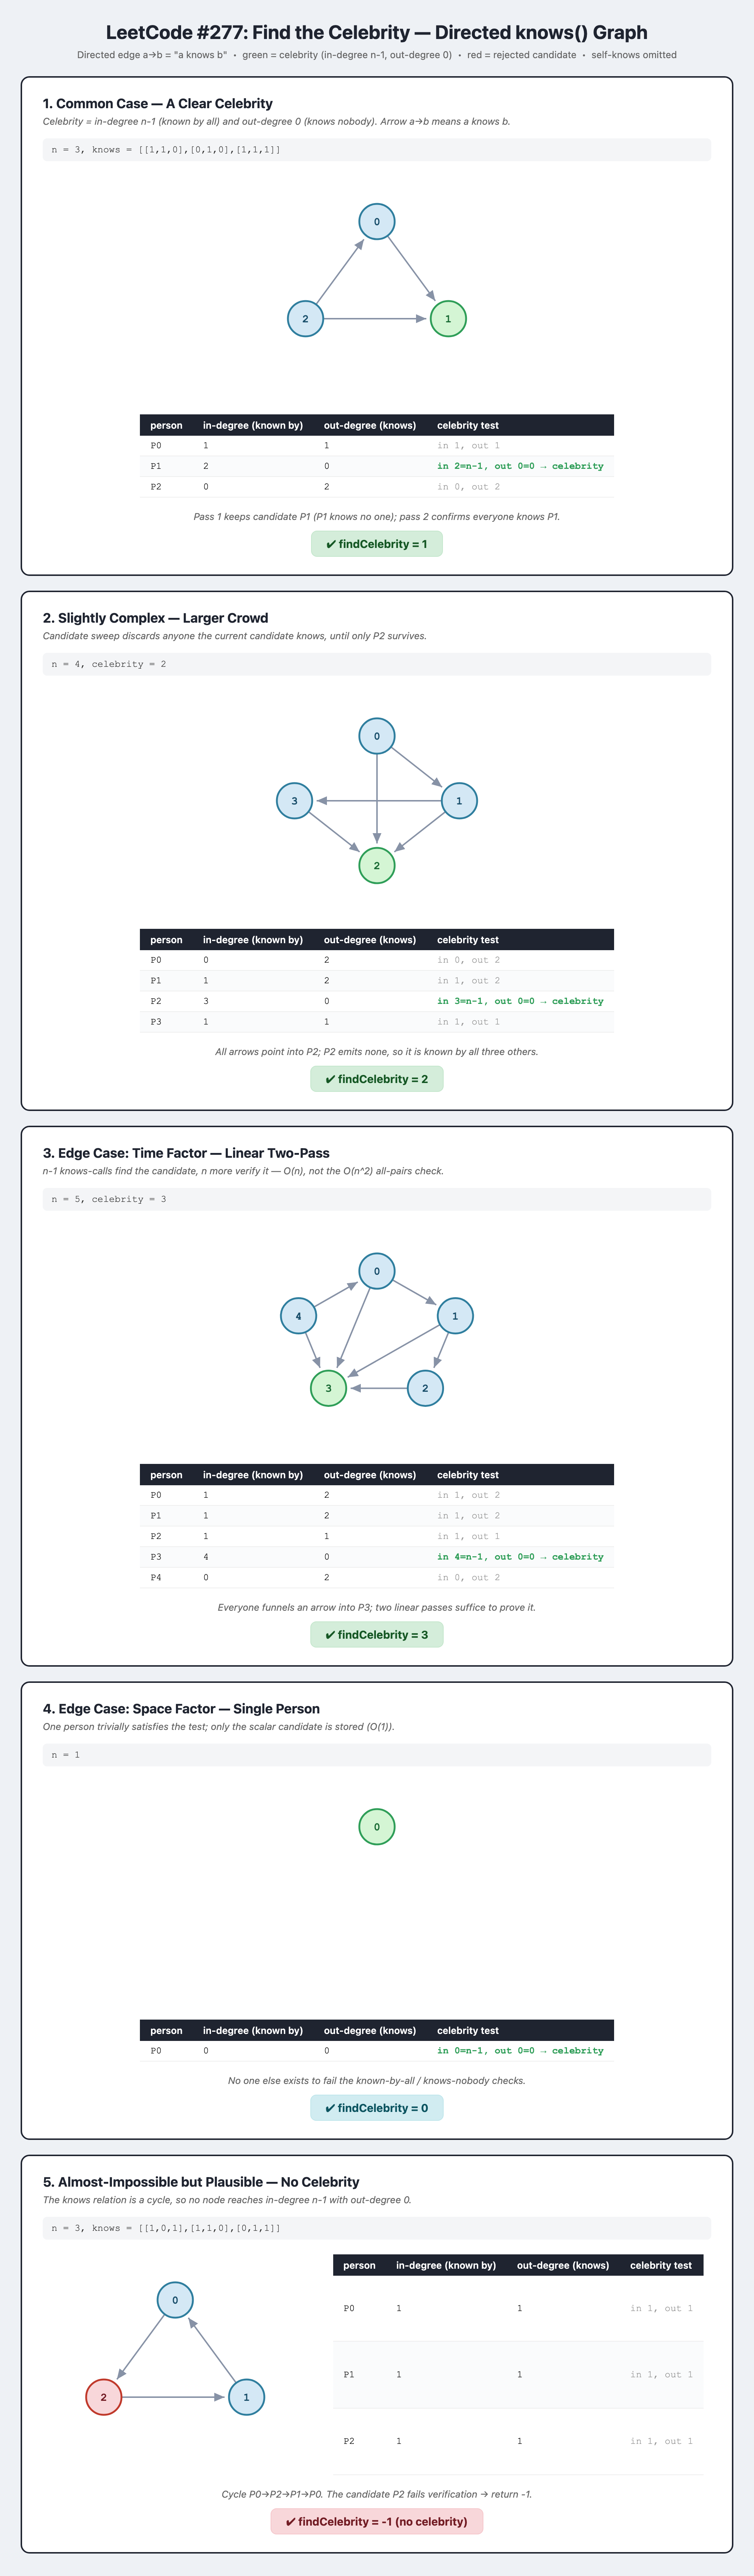